# PaddleOCR-VL — Document Layout Analysis Pipeline

Pipeline phân tích layout tài liệu dùng **PaddleOCR / PaddleX** (model mặc định: `PP-DocLayout_plus-L`). Notebook thực hiện:
1. **Chạy inference**: Phát hiện layout bounding box trên các ảnh tài liệu, xuất kết quả JSON chuẩn COCO.
2. **Đánh giá metric**: Tính Precision, Recall, F1 theo chuẩn Strict (vị trí + nhãn) và Loose (chỉ vị trí), xuất biểu đồ phân tích.
3. **Trực quan hóa**: Đối chiếu ảnh Ground Truth và dự đoán của PaddleOCR cạnh nhau để trực quan kết quả.

### Chiến lược mapping và lọc nhãn (Taxonomy Mapping)
PaddleOCR PP-DocLayout có 20 nhãn chi tiết; tập dữ liệu DocLayNet chuẩn có 11 nhãn. Script tự động áp dụng chiến lược mapping tối ưu:
- **Khớp trực tiếp**: `table` -> `Table`, `formula` -> `Formula`, `footnote` -> `Footnote`.
- **Ảnh & Đồ thị**: `image`, `chart` -> `Picture`.
- **Tiêu đề & Đề mục**: `doc_title` -> `Title`, `paragraph_title` -> `Section-header`.
- **Chú thích**: `figure_title`, `table_title`, `chart_title` -> `Caption`.
- **Đầu/chân trang**: `header`, `header_image` -> `Page-header`; `footer`, `footer_image` -> `Page-footer`.
- **Văn bản & Nội dung**: `text`, `abstract`, `content`, `reference`, `aside_text`, `algorithm` -> `Text`.
- **Nhãn loại bỏ (`DEFAULT_DROP_LABELS`)**: `seal` (con dấu - không tồn tại trong DocLayNet), `formula_number` (đánh số công thức - thuộc khối công thức), `number` (số rời rạc - 80% là false positive). Việc loại bỏ các nhãn này giúp tăng Precision (+4.7%) và F1 (+2.6%) mà không làm giảm Recall.

In [1]:
from pathlib import Path
import subprocess
import sys

# Nạp torch trước trên Windows để tránh xung đột thư viện DLL giữa Paddle và PyTorch
try:
    import torch
except ImportError:
    pass

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "methods").is_dir():
    raise FileNotFoundError("Không tìm thấy thư mục gốc repository; hãy mở notebook từ project DO-AN-261.")

METHOD = "paddleocr_vl"
DATASET = "doclaynet"
SPLIT = "train"
IOU_THRESHOLD = 0.5
LIMIT = 20  # 0: toàn bộ ảnh trong tập dữ liệu; hoặc giới hạn số ảnh (vd: 20 để test nhanh)
FORCE_INFERENCE = False  # True: chạy lại inference và ghi đè; False: bỏ qua ảnh đã có prediction
FIGURE_LIMIT = 20

PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
FIGURES_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
print(f"Project: {ROOT}")
print(f"Pipeline: {METHOD} | {DATASET}/{SPLIT} | IoU >= {IOU_THRESHOLD}")
print(f"Inference: {'force rerun' if FORCE_INFERENCE else 'skip existing predictions'}")
print(f"Predictions: {PREDICTIONS_DIR}")
print(f"Figures: {FIGURES_DIR}")


Project: D:\Semester_261\DoAnChuyenNganh\DO-AN-261
Pipeline: paddleocr_vl | doclaynet/train | IoU >= 0.5
Inference: skip existing predictions
Predictions: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\paddleocr_vl\doclaynet
Figures: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\paddleocr_vl_doclaynet


## 1. Prediction

Chạy layout detection bằng script `methods/paddleocr_vl/src/run_inference.py`. Script tự động tải model `PP-DocLayout_plus-L` lần đầu (nếu chưa có cache) và sinh kết quả dự đoán ra `outputs/predictions/paddleocr_vl/<dataset>/`.

In [2]:
inference_script = ROOT / "methods" / METHOD / "src" / "run_inference.py"
command = [
    sys.executable,
    str(inference_script),
    "--dataset", DATASET,
    "--limit", str(LIMIT),
    "--force" if FORCE_INFERENCE else "--skip-existing",
]
print("Running:", " ".join(command))
res = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)
print(f"Predictions: {PREDICTIONS_DIR}")


Running: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\paddleocr_vl\src\run_inference.py --dataset doclaynet --limit 20 --skip-existing


[paddleocr_vl] 0 image(s) to predict from D:\Semester_261\DoAnChuyenNganh\DO-AN-261\datasets\doclaynet\processed\images (model: PP-DocLayout_plus-L, threshold: 0.3) (existing predictions skipped)
[paddleocr_vl] Mapping strategy: 21 mapped labels, 3 dropped labels: formula_number, number, seal
[paddleocr_vl] No work to do. Predictions are in D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\paddleocr_vl\doclaynet

Predictions: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\paddleocr_vl\doclaynet


## 2. Metrics and Evaluation Chart

Đánh giá kết quả trên tập ảnh vừa thực thi inference (`outputs/predictions/paddleocr_vl/doclaynet/`).
- **Strict**: Yêu cầu khớp cả tọa độ (IoU >= threshold) và đúng nhãn layout.
- **Loose**: Chỉ đánh giá khả năng định vị (localization), bỏ qua nhãn.
- **Biểu đồ**: Trực quan hóa Precision, Recall, F1 theo từng class và so sánh Strict vs Loose.

Running evaluation:


Evaluation: paddleocr_vl on doclaynet/train | 20 images | GT=250 boxes | Predictions=315 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.667  Recall=0.840  F1=0.743  TP=210 FP=105 FN=40  mean IoU=0.826
Macro (mean across 9 ground-truth classes): Precision=0.408  Recall=0.594  F1=0.451
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                   140     151    126     25     14    0.834    0.900    0.866
Section-header          50      82     49     33      1    0.598    0.980    0.742
Table                   20      21     20      1      0    0.952    1.000    0.976
Page-footer             17       8      3      5     14    0.375    0.176    0.240
Page-header              7       8      2      6      5    0.250    0.286    0.267
Picture                  6      13      6      7      0    0.462    1.000    0.632
Caption                  4      20      4     16      0    0.200    1.000    0.333
Footnote               

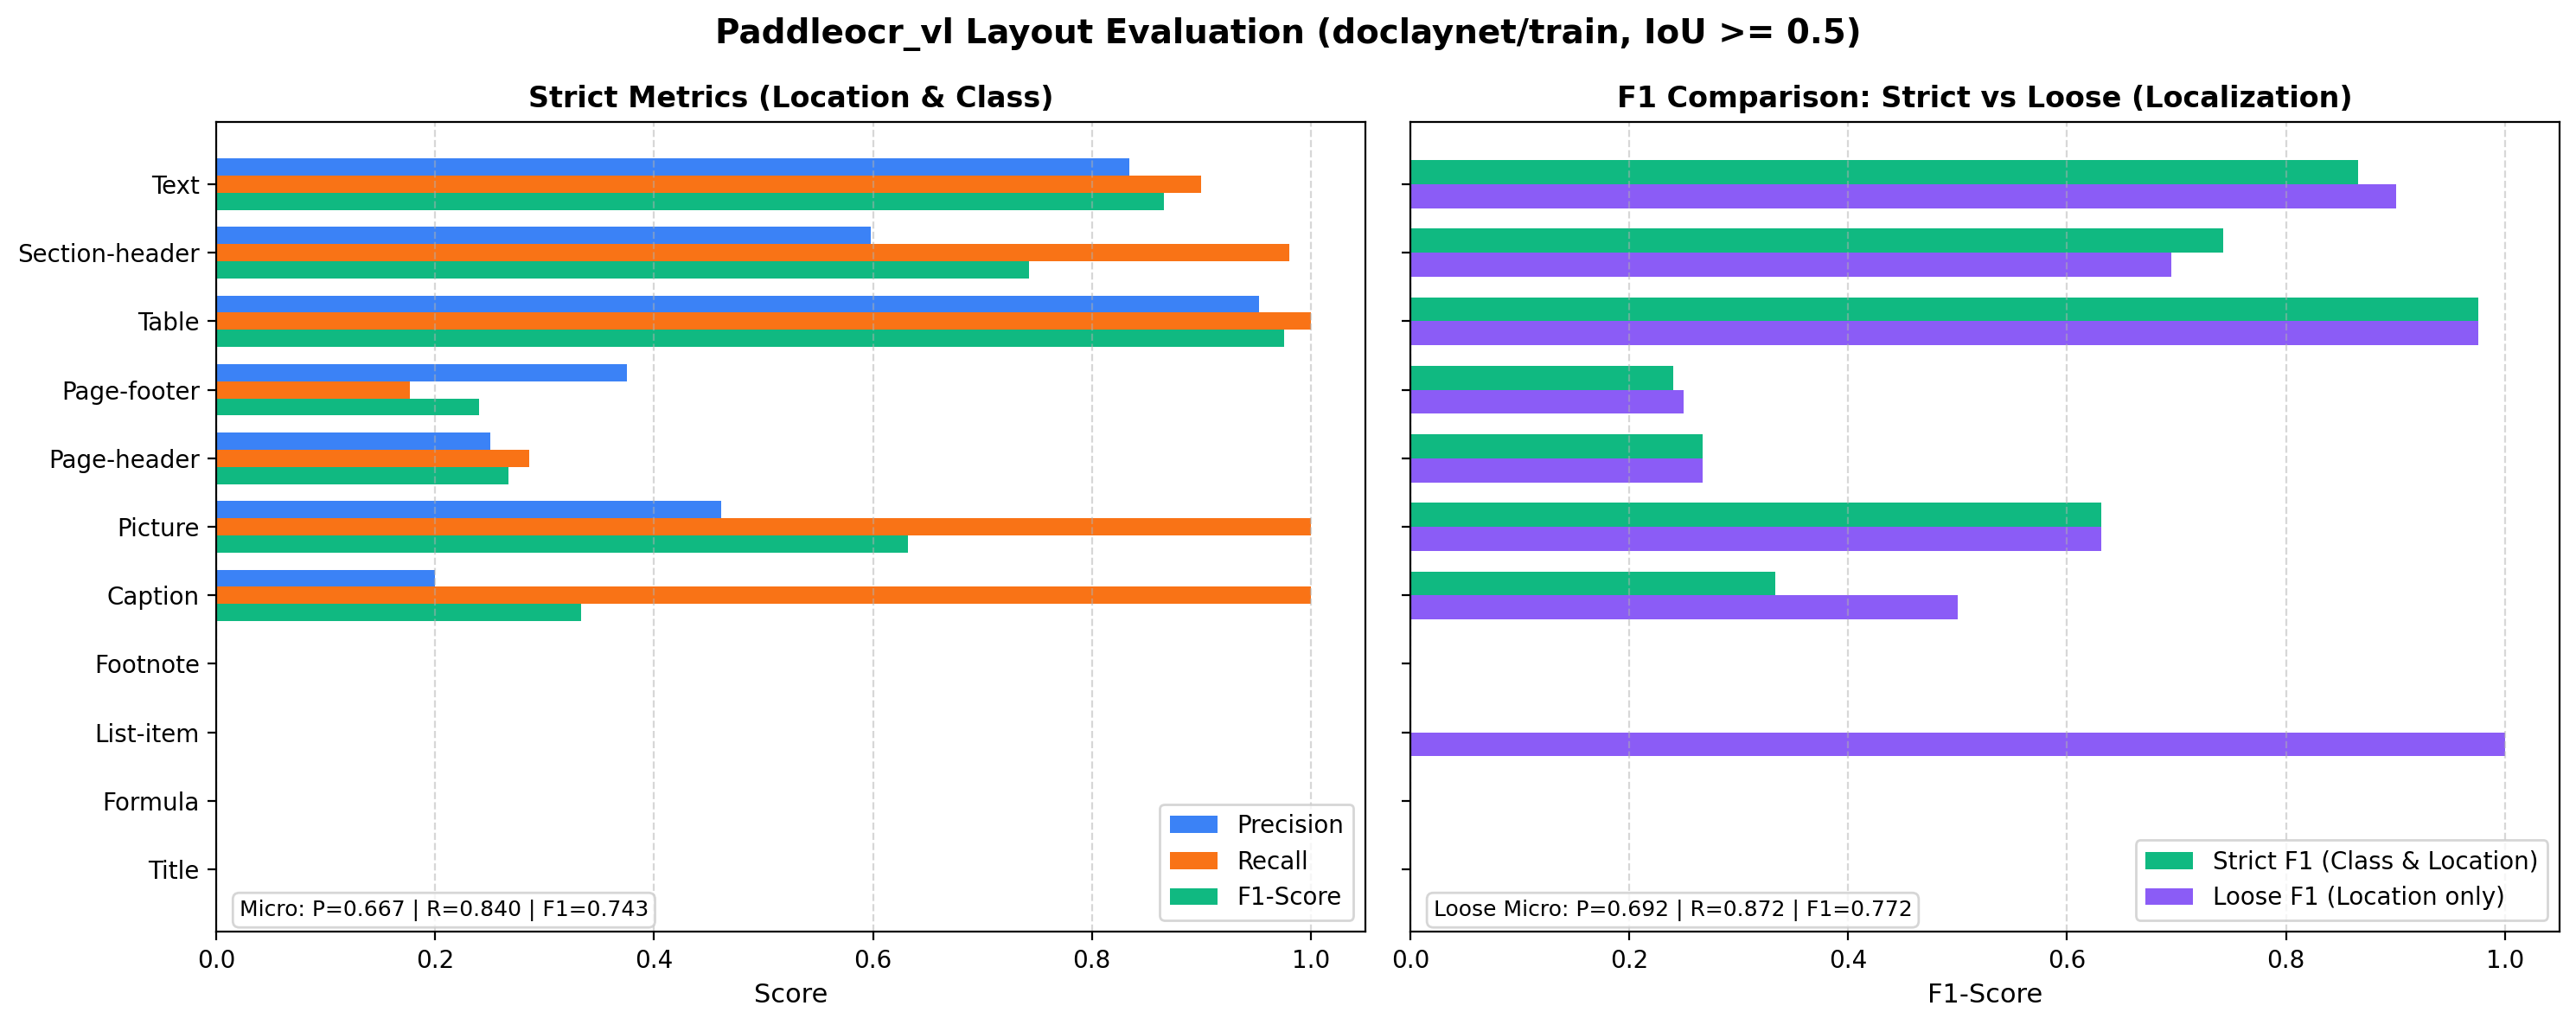

In [3]:
evaluation_script = ROOT / "scripts" / "evaluate_predictions.py"
chart_file = FIGURES_DIR / "metrics_chart.png"
command = [
    sys.executable,
    str(evaluation_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", str(IOU_THRESHOLD),
    "--loose",
    "--allow-incomplete",
    "--plot", str(chart_file),
]
print("Running evaluation:")
res = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)

# Hiển thị biểu đồ đánh giá
if chart_file.is_file():
    from IPython.display import Image as DisplayImage, display
    print(f"Evaluation Chart ({chart_file}):")
    display(DisplayImage(filename=str(chart_file)))


## 3. Ground Truth vs. Prediction Examples

Trực quan hóa đối chiếu ảnh Ground Truth và kết quả dự đoán của PaddleOCR. Ảnh kết quả được lưu tại `outputs/reports/paddleocr_vl_doclaynet/`.

Running: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\visualize_predictions.py --method paddleocr_vl --dataset doclaynet --split train --limit 20 --output-dir D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\paddleocr_vl_doclaynet


[viz] Ve 20 anh (paddleocr_vl vs ground truth) tu D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\..\..\outputs\predictions\paddleocr_vl\doclaynet
  [ok] 0.png
  [ok] 1.png
  [ok] 2.png
  [ok] 3.png
  [ok] 4.png
  [ok] 5.png
  [ok] 6.png
  [ok] 7.png
  [ok] 8.png
  [ok] 9.png
  [ok] 10.png
  [ok] 12.png
  [ok] 13.png
  [ok] 14.png
  [ok] 15.png
  [ok] 16.png
  [ok] 17.png
  [ok] 18.png
  [ok] 19.png
  [ok] 20.png
[viz] Xong. Anh luu tai D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\paddleocr_vl_doclaynet

Ví dụ ảnh đối chiếu: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\paddleocr_vl_doclaynet\0.png


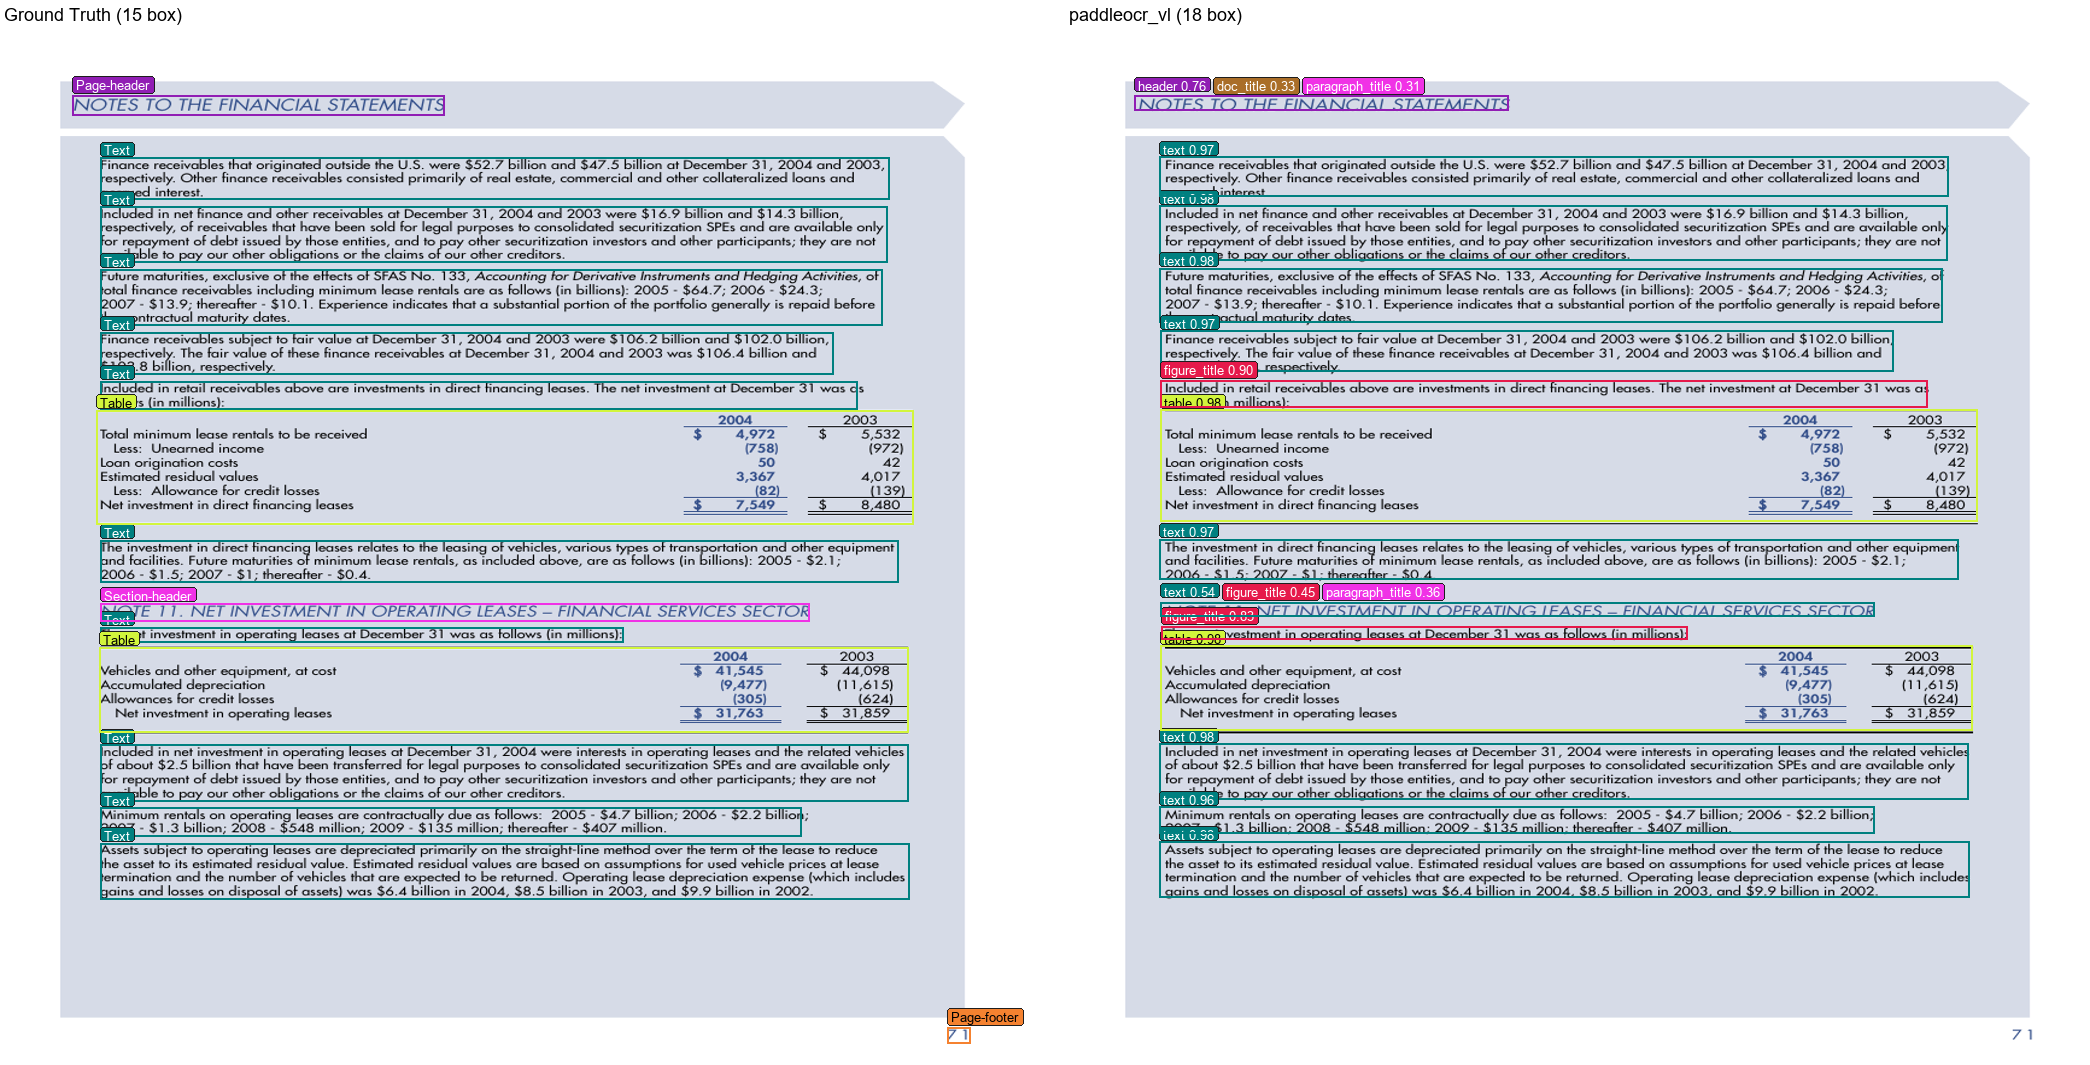

In [4]:
visualizer = ROOT / "visualization" / "scripts" / "visualize_predictions.py"
command = [
    sys.executable,
    str(visualizer),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", str(FIGURE_LIMIT),
    "--output-dir", str(FIGURES_DIR),
]
print("Running:", " ".join(command))
res = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)

figure_files = sorted(
    FIGURES_DIR.glob("*.png"),
    key=lambda path: (0, int(path.stem)) if path.stem.isdigit() else (1, path.stem),
)
# Lọc bỏ file metrics_chart.png để chỉ hiển thị ảnh đối chiếu box
example_figures = [f for f in figure_files if f.name != "metrics_chart.png"]
if example_figures:
    from IPython.display import Image as DisplayImage, display
    print(f"Ví dụ ảnh đối chiếu: {example_figures[0]}")
    display(DisplayImage(filename=str(example_figures[0])))
else:
    print(f"Không có hình ảnh đối chiếu nào trong {FIGURES_DIR}")


## Files đầu ra và báo cáo

- Predictions JSON: `outputs/predictions/paddleocr_vl/doclaynet/<image_id>.json`
- Biểu đồ đánh giá: `outputs/reports/paddleocr_vl_doclaynet/metrics_chart.png`
- Ảnh đối chiếu trực quan: `outputs/reports/paddleocr_vl_doclaynet/<image_id>.png`
- Ground Truth COCO: `datasets/doclaynet/processed/annotations/train.json`